# Figure 4：Pathway Enrichment Analysis of DEGs in C0 and C1

In [1]:
suppressPackageStartupMessages({
  library(ggplot2)
  library(dplyr)
  library(Matrix)
  library(stringr)
  library(clusterProfiler)
  library(org.Hs.eg.db)
  library(msigdbr)
})

In [2]:
deg_c0 <- read.csv('./Outputs/Xenium_Prime_Ovarian_Cancer_Subclusters/DEGs_0.csv', check.names = F)
deg_c1 <- read.csv('./Outputs/Xenium_Prime_Ovarian_Cancer_Subclusters/DEGs_1.csv', check.names = F)
head(deg_c0)

,,names,scores,pvals,pvals_adj,logfoldchanges,logfoldchanges_celltype
,<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,TIMP3,89.58227,0.000000e+00,0.000000e+00,2.1743603,3.009299
2,1,SFRP4,50.48513,0.000000e+00,0.000000e+00,2.3915782,3.383569
3,2,THBS1,37.73944,0.000000e+00,0.000000e+00,1.1881280,2.735064
4,3,CCN2,37.13971,6.426062e-302,2.730541e-299,1.1668078,3.482413
5,4,LUM,31.69168,2.023025e-220,4.126162e-218,0.4366394,4.616579
6,5,DCN,31.34108,1.287013e-215,2.343742e-213,0.3829585,2.966024


In [3]:
markers_c0 <- deg_c0$names[deg_c0$logfoldchanges > 0.2 & deg_c0$pvals_adj < 0.05 & deg_c0$logfoldchanges_celltype > 0] 
markers_c1 <- deg_c1$names[deg_c1$logfoldchanges > 0.2 & deg_c1$pvals_adj < 0.05 & deg_c1$logfoldchanges_celltype > 0]

run_enrichment <- function(markers){
  entrez_genes <- bitr(markers, fromType="SYMBOL", toType="ENTREZID", OrgDb=org.Hs.eg.db)
  go_bp <- enrichGO(gene=entrez_genes$ENTREZID, OrgDb=org.Hs.eg.db, keyType="ENTREZID", ont="BP",
                    pvalueCutoff=0.05, qvalueCutoff=0.2, readable=TRUE)
}
gobp_c0 <- run_enrichment(markers_c0)
gobp_c1 <- run_enrichment(markers_c1)
gobp_c0 <- gobp_c0[which(gobp_c0$p.adjust < 0.01 & gobp_c0$qvalue < 0.01), ]
gobp_c1 <- gobp_c1[which(gobp_c1$p.adjust < 0.01 & gobp_c1$qvalue < 0.01), ]

'select()' returned 1:1 mapping between keys and columns

'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(markers, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Hs.eg.db):
“0.15% of input gene IDs are fail to map...”


In [4]:
c0_term <- c('extracellular matrix organization','extracellular structure organization',
             'cellular response to fibroblast growth factor stimulus', 'connective tissue development', 'collagen fibril organization')
c1_term <- c('cellular response to external stimulus','regulation of apoptotic signaling pathway',
             'response to oxygen levels','response to nutrient levels', 'response to hypoxia')
gobp_c0_display <- gobp_c0[which(gobp_c0$Description %in% c0_term), ]
gobp_c0_display$Direction <- "C0"

gobp_c1_display <- gobp_c1[which(gobp_c1$Description %in% c1_term), ]
gobp_c1_display$Direction <- "C1"

gobp_df <- rbind(gobp_c0_display, gobp_c1_display)
gobp_df$GeneRatio <- sapply(strsplit(as.character(gobp_df$GeneRatio), "/"),
                            function(x) as.numeric(x[1]) / as.numeric(x[2]))
gobp_df$log_padj <- -log10(gobp_df$p.adjust)
gobp_df$Description <- paste0(toupper(substr(gobp_df$Description, 1, 1)),
                              tolower(substr(gobp_df$Description, 2, nchar(gobp_df$Description))))
gobp_df$Direction <- factor(gobp_df$Direction, levels=c("C0", "C1"), ordered=TRUE)
gobp_df <- gobp_df[order(gobp_df$Direction, gobp_df$GeneRatio), ]

write.csv(gobp_df, "./Outputs/Figure4_CAF_subtypes_GOBP_Enrichment_pathway.csv")

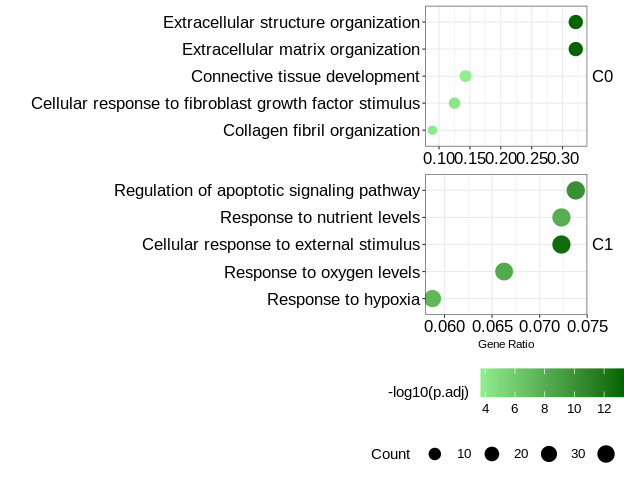

In [5]:
gobp_df$Description_plot <- paste0(gobp_df$Direction, "___", gobp_df$Description) 
gobp_df$Description_plot <- factor(gobp_df$Description_plot, levels=unique(gobp_df$Description_plot))

p1 <- ggplot(gobp_df, aes(x=GeneRatio, y=Description_plot)) +
  geom_point(aes(size=Count, color=log_padj)) +
  facet_wrap(~Direction, ncol=1, scales="free", strip.position="right") +
  scale_y_discrete(labels=function(x) sub("^.*___", "", x)) +
  scale_x_continuous(
    expand=expansion(mult=c(0.05, 0.08))
  ) +
  scale_color_gradient(
    low="lightgreen",
    high="darkgreen",
    name="-log10(p.adj)"
  ) +
  scale_size_continuous(
    name="Count",
    range=c(2, 4.5)
  ) +
  labs(x="Gene Ratio", y="") +
  theme_bw(base_size=7) +
  theme(
    axis.text.x=element_text(size=10, color="black"),
    axis.text.y=element_text(size=10, color="black"),
    legend.position="bottom",
    legend.box="vertical",
    legend.title=element_text(size=9, color="black"),
    legend.text=element_text(size=8, color="black"),
    strip.background=element_blank(),
    strip.placement="outside",
    strip.text.y.right=element_text(
      size=10,
      color="black",
      angle=0
    )
  )

options(repr.plot.width=5.2, repr.plot.height=4)
print(p1)
